In [50]:
import numpy as np
import pandas as pd
import math as mt
import matplotlib.pyplot as plt

In [195]:
df = pd.read_excel("NFLX_DS_data_8_22.xlsx")
df_rating = pd.read_excel("NFLX_DS_data_8_22.xlsx", sheet_name="IMDb Rating")
df_time = pd.read_excel("NFLX_DS_data_8_22.xlsx", sheet_name="Runtime")

1.1) The TV show with the most appearances in the top 10 list is *You*, appears 18 times.

1.2) Average weekly viewed hours for *You* is about 4319333.33 hrs.

In [27]:
df[df.category == "TV (English)"].groupby('show_title').size().sort_values(ascending=False).head(1)

show_title
You    18
dtype: int64

In [173]:
hrs = df[df.show_title == "You"]["weekly_hours_viewed"]
hrs.sum() / hrs.count()

43193333.333333336

2) The film with the lowest IMDb rating is *Love Me Instead* of rating $2.1$, its average weekly hours viewed is $4440000$.

In [225]:
non_zero = df_rating[df_rating.rating > 0]
non_zero['title'] = non_zero['title'].apply(lambda x: str(x)) # normalize
non_zero['rating'] = non_zero['rating'].apply(lambda x: float(x))
non_zero = non_zero.groupby(['title']).median().reset_index(0)
non_zero

C:\Users\35995\AppData\Local\Temp\ipykernel_35564\3728746844.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_zero['title'] = non_zero['title'].apply(lambda x: str(x)) # normalize
C:\Users\35995\AppData\Local\Temp\ipykernel_35564\3728746844.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_zero['rating'] = non_zero['rating'].apply(lambda x: float(x))


,title,rating
0,#Roxy,5.1
1,(T)ERROR,6.6
2,(Un)Well,6.4
3,07:19:00,5.9
4,1 Chance 2 Dance,4.8
...,...,...
12866,風が強く吹いている,6.4
12867,내 머리 속의 지우개,8.2
12868,넌 내게 반했어,7.2
12869,올드보이,8.4


In [226]:
jn = df[df.category == "Films (Non-English)"].join(non_zero)
jn[jn.rating > 0].sort_values("rating").head(1)

,category,cumulative_weeks_in_top_10,weekly_hours_viewed,season_title,weekly_rank,show_title,date_added,week,title,rating
752,Films (Non-English),2,5880000,NaN,4,Love Me Instead,2022-01-04,2021-11-28,American Poltergeist,2.1


In [227]:
mov = df[df.show_title == "Love Me Instead"]
ave = mov.sum()["weekly_hours_viewed"] / len(mov)
ave

C:\Users\35995\AppData\Local\Temp\ipykernel_35564\711895259.py:2: FutureWarning: The default value of numeric_only in DataFrame.sum is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  ave = mov.sum()["weekly_hours_viewed"] / len(mov)


4440000.0

3.1) The English film with the most cumulative weeks is *Red Notice*. 13 weeks.

3.2) The length of this movie is about $118$ minutes, as we can see from the figure and table, as time goes, the weekly viewed hours of *Red Notice* is descending. Hence we can take the sum of weekly viewed hours and divide it by the length of the movie, then get the number of audience.

There are generally $2$ risks to this approach, 

- some audience may like this movie a lot, and decided to watch it multiple times, hence our result may be larger.
- some audience may be not included in the table, for example, they may watch it on other websites.

By our approach, the number of audience is about $395328813$.

In [49]:
most_cu = df[df.category == "Films (English)"].sort_values("cumulative_weeks_in_top_10", ascending=False)
most_cu.head(1)["show_title"]

449    Red Notice
Name: show_title, dtype: object

In [52]:
red_notice = most_cu[df.show_title == "Red Notice"]
red_notice

C:\Users\35995\AppData\Local\Temp\ipykernel_35564\2220705591.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  red_notice = most_cu[df.show_title == "Red Notice"]


,category,cumulative_weeks_in_top_10,weekly_hours_viewed,season_title,weekly_rank,show_title,date_added,week
449,Films (English),13,4970000,NaN,10,Red Notice,2022-03-01,2022-02-27
358,Films (English),12,6540000,NaN,6,Red Notice,2022-02-01,2022-01-30
374,Films (English),11,7310000,NaN,8,Red Notice,2022-01-25,2022-01-23
41,Films (English),10,8710000,NaN,6,Red Notice,2022-01-18,2022-01-16
716,Films (English),9,11090000,NaN,6,Red Notice,2022-01-11,2022-01-09
720,Films (English),8,14540000,NaN,5,Red Notice,2022-01-04,2022-01-02
1260,Films (English),7,12140000,NaN,7,Red Notice,2022-01-04,2021-12-26
753,Films (English),6,12710000,NaN,4,Red Notice,2022-01-04,2021-12-19
557,Films (English),5,18010000,NaN,2,Red Notice,2022-01-04,2021-12-12
810,Films (English),4,25400000,NaN,3,Red Notice,2022-01-04,2021-12-05


Text(0, 0.5, 'Weekly viewed hours')

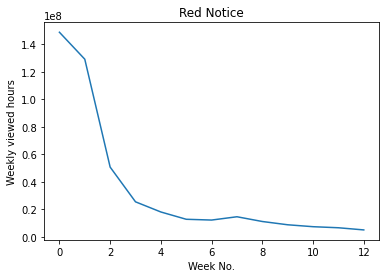

In [63]:
hrs = np.flip(np.array(red_notice["weekly_hours_viewed"]))
xs = np.array(range(len(hrs)))

fig = plt.figure(1)
plt.plot(xs, hrs)
plt.title("Red Notice")
plt.xlabel("Week No.")
plt.ylabel("Weekly viewed hours")

In [235]:
# approximate count of audiences
hrs.sum() / (float(df_time[df_time.title == "Red Notice"]["runtime"]) / 60)

395328813.55932206

4) From the graph, we can see the following trend over time:

- Viewed hours of *Films (Non-English)* have no significant changes over time.
- Viewed hours of *Films (English)* have peaks in the late summer and winter of 2021.
- People watched *TV (Non-English)* most (reached peaks) in 2021-10, 2021-12, 2022-02 (Probably due to trend episodes)
- People watched *TV (English)* least (reached valleys) in 2021-09, 2021-12, but the total viewed hours of this category slightly increased over time.

In [92]:
cat_week = df.groupby(["category", "week"]).sum("weekly_hours_viewed")["weekly_hours_viewed"].reset_index(name="sum")
cat_week

,category,week,sum
0,Films (English),2021-07-04,114650000
1,Films (English),2021-07-11,113970000
2,Films (English),2021-07-18,114020000
3,Films (English),2021-07-25,109540000
4,Films (English),2021-08-01,96860000
...,...,...,...
139,TV (Non-English),2022-02-06,478020000
140,TV (Non-English),2022-02-13,314560000
141,TV (Non-English),2022-02-20,239250000
142,TV (Non-English),2022-02-27,173640000


Text(0.5, 1.0, 'Viewed hours of different categories')

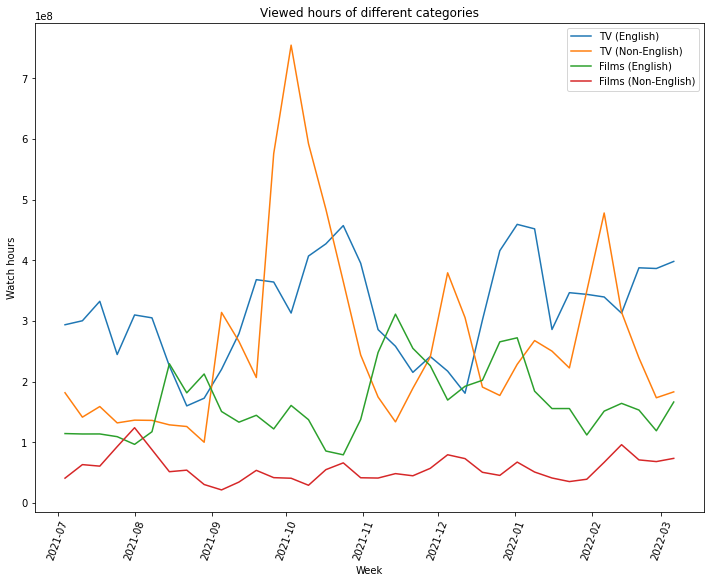

In [113]:
tv_eng = cat_week[cat_week.category == "TV (English)"]
tv_non_eng = cat_week[cat_week.category == "TV (Non-English)"]
film_eng = cat_week[cat_week.category == "Films (English)"]
film_non_eng = cat_week[cat_week.category == "Films (Non-English)"]

plt.figure(2, figsize=(12, 9))
plt.plot(tv_eng["week"], tv_eng["sum"], label="TV (English)")
plt.plot(tv_non_eng["week"], tv_non_eng["sum"], label="TV (Non-English)")
plt.plot(film_eng["week"], film_eng["sum"], label="Films (English)")
plt.plot(film_non_eng["week"], film_non_eng["sum"], label="Films (Non-English)")
plt.legend()
plt.xticks(rotation=70)
plt.xlabel("Week")
plt.ylabel("Watch hours")
plt.title("Viewed hours of different categories")

5)

6) Reasons:

- Some of the dataset may be inaccurate or out-of-date.
- Some data may be wrongly categorized when scraping, for example, wrong rows are selected or null data is scraped due to dynamic generated DOM elements.
- The definition of a term used by the dataset may be inaccurate, not well-defined or different from our explanation. 